In [1]:
from google.colab import files
uploaded = files.upload()   # choose BEED_Data_Split.xlsx when the dialog opens
file_path = list(uploaded.keys())[0]
print("Loaded:", file_path)

Saving BEED_Data_Split.xlsx to BEED_Data_Split.xlsx
Loaded: BEED_Data_Split.xlsx


Dataset shape: (5600, 17)
Columns in dataset: ['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'y']
Using target column: y

CART Model Accuracy: 0.8333

Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.97      0.98       396
           1       0.82      0.81      0.82       425
           2       0.81      0.79      0.80       430
           3       0.73      0.78      0.76       429

    accuracy                           0.83      1680
   macro avg       0.84      0.84      0.84      1680
weighted avg       0.84      0.83      0.83      1680



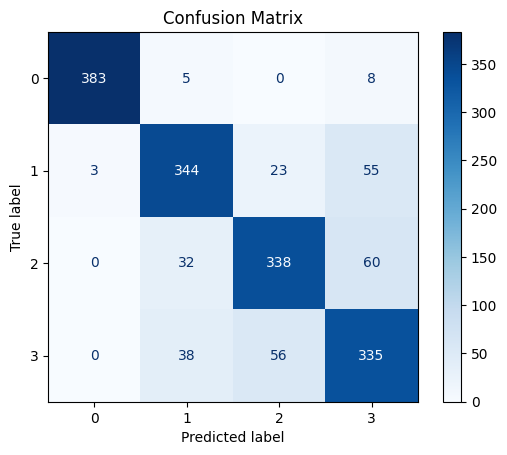

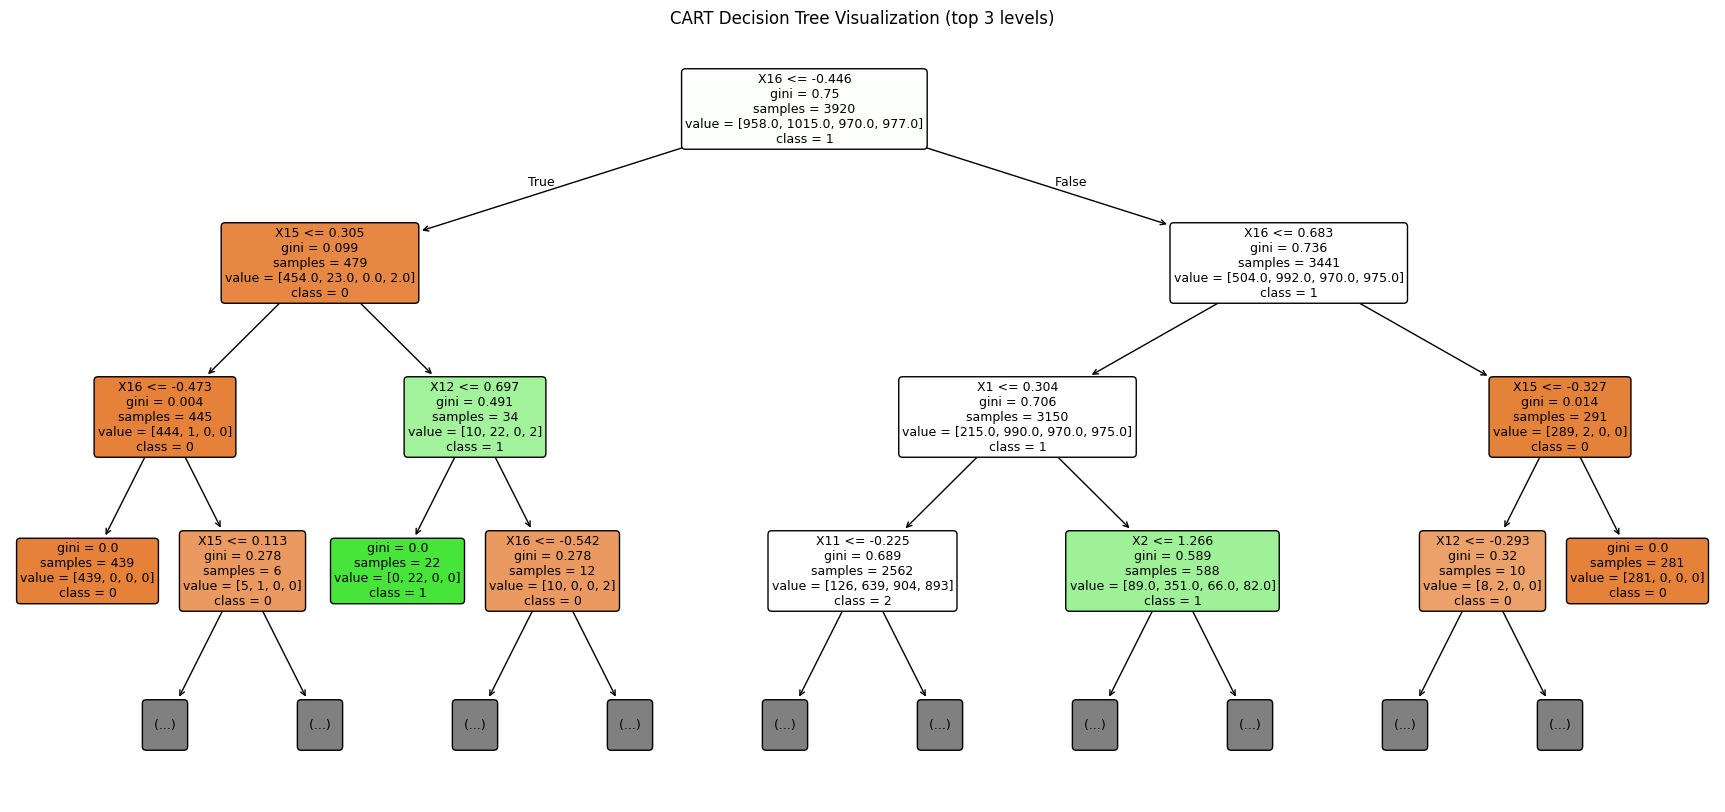

Full tree depth: 27 | Leaves: 394


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# 1) Load dataset and preprocessing
df = pd.read_excel(file_path, sheet_name=0)   # first sheet ("Train"), same as your VS Code run

df.replace(['?', 'unknown'], np.nan, inplace=True)
df.dropna(inplace=True)

print("Dataset shape:", df.shape)
print("Columns in dataset:", df.columns.tolist())

target_col = df.columns[-1]
print("Using target column:", target_col)

X = df.drop(columns=[target_col])
y = df[target_col]

# Encode categorical columns (none here, but kept for safety)
for col in X.select_dtypes(include=['object']).columns:
    X[col] = LabelEncoder().fit_transform(X[col])

if y.dtype == 'object':
    y = LabelEncoder().fit_transform(y)

# Normalize numeric columns
num_cols = X.select_dtypes(include=[np.number]).columns
X[num_cols] = StandardScaler().fit_transform(X[num_cols])

# Train-test split (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# 2) CART algorithm (Decision Tree)
cart = DecisionTreeClassifier(criterion='gini', random_state=42)
cart.fit(X_train, y_train)
y_pred_cart = cart.predict(X_test)

# 3) Model evaluation
accuracy = accuracy_score(y_test, y_pred_cart)
print(f"\nCART Model Accuracy: {accuracy:.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred_cart))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_cart)
ConfusionMatrixDisplay(cm).plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

# 4) Visualize the decision tree (top 3 levels so it is readable)
class_names = [str(c) for c in sorted(np.unique(y))]
plt.figure(figsize=(22, 10))
plot_tree(cart, max_depth=3, filled=True, feature_names=X.columns.tolist(),
          class_names=class_names, rounded=True, fontsize=9)
plt.title("CART Decision Tree Visualization (top 3 levels)")
plt.show()

print("Full tree depth:", cart.get_depth(), "| Leaves:", cart.get_n_leaves())